# Determining null size for mAP p-value calculation

Recorded results and timings below predate the 0.6.0 adjustments and have not been regenerated. Rerun for your installed version; see the [migration notes](../migration-0.6.0.md). `null_size=0` now returns scores with untested statistical outputs, while positive sizes always run the requested Monte Carlo draws.

In [1]:
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import comb

from copairs import map
from copairs.matching import assign_reference_index

In [2]:
def plot_scatter_grid(
    data,
    null_size_col="null_size",
    x_col="mAP",
    y_col="-log10(p-value)",
    color_col="below_corrected_p",
    cmap="tab10",
    figsize=(12, 6),
):
    """Plot a grid of scatter plots for different values of a given column.

    Args:
        data (pd.DataFrame): Input DataFrame containing the data.
        null_size_col (str): Column to split data into subplots. Defaults to "null_size".
        x_col (str): Column to use for the x-axis. Defaults to "mean_average_precision".
        y_col (str): Column to use for the y-axis. Defaults to "-log10(p-value)".
        color_col (str): Column for coloring points. Defaults to "below_corrected_p".
        cmap (str): Colormap for the scatter plot. Defaults to "tab10".
        figsize (tuple): Figure size. Defaults to (12, 6).
    """
    unique_null_sizes = sorted(data[null_size_col].unique())  # Get unique values
    n_rows, n_cols = 3, 4  # Define grid shape

    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize, sharex=True, sharey=True)
    axes = axes.flatten()  # Flatten for easy iteration

    for i, null_size in enumerate(unique_null_sizes):
        ax = axes[i]
        subset = data[data[null_size_col] == null_size]  # Filter data for current panel

        # Compute active ratio for the subset
        active_ratio = subset[color_col].mean()

        # Scatter plot
        _ = ax.scatter(
            subset[x_col], subset[y_col], c=subset[color_col], cmap=cmap, s=10
        )

        ax.axhline(
            -np.log10(0.05), color="black", linestyle="--"
        )  # Significance threshold
        ax.set_title(f"{null_size_col} = {null_size}")

        # Display active ratio per panel
        ax.text(
            0.4,
            5,
            f"Active = {100 * active_ratio:.2f}%",
            va="center",
            ha="left",
            fontsize=9,
        )

        if i % n_cols == 0:  # Leftmost column
            ax.set_ylabel(y_col)
        if i >= (n_rows - 1) * n_cols:  # Bottom row
            ax.set_xlabel(x_col)

    fig.suptitle(f"Scatter plots across different {null_size_col} values", fontsize=14)
    plt.tight_layout(rect=[0, 0.05, 1, 0.95])  # Adjust layout
    plt.show()

## Load data

This example uses the plate downloaded in the [Phenotypic activity](./phenotypic_activity.ipynb) example, so run that one first if you haven't.

The default `null="permutation"` needs the pairs that `average_precision` attaches to the AP frame it returns. They are lost when the frame is saved, so instead of loading `data/activity_ap.csv` we recompute the APs here the same way.

In [3]:
df = pd.read_csv("data/2016_04_01_a549_48hr_batch1_plateSQ00014812.csv")
df = df.loc[:, df.nunique() > 1]  # remove constant columns

reference_col = "Metadata_reference_index"
df_activity = assign_reference_index(
    df,
    "Metadata_broad_sample == 'DMSO'",
    reference_col=reference_col,
    default_value=-1,
)
pos_sameby = ["Metadata_broad_sample", reference_col]
neg_diffby = ["Metadata_broad_sample", reference_col]

metadata = df_activity.filter(regex="^Metadata")
profiles = df_activity.filter(regex="^(?!Metadata)").values
activity_ap = map.average_precision(
    metadata, profiles, pos_sameby, [], [], neg_diffby, progress_bar=False
)
activity_ap = activity_ap.query("Metadata_broad_sample != 'DMSO'")  # remove DMSO

## Complete null size

We estimate the statistical significance of a mAP score with respect to a random baseline using a permutation test of the null hypothesis that the compound's profiles and the control profiles are exchangeable. Under this hypothesis, any of the profiles a compound's replicates are ranked against could have carried the compound's label. The permutation null draws such relabellings and recomputes the mAP from the observed similarities.

Let $m$ be the number of replicates of a compound and $n$ the number of control profiles they are ranked against. A relabelling picks which $m$ of the $m + n$ profiles carry the compound's label, so the complete null has

\begin{equation}
    d_{null} = \binom{m + n}{m}
\end{equation}

relabellings, one of which is the observed one. When the profiles are ranked against different sets of controls (e.g. one plate each), the counts of the blocks multiply. (The copied null, `null="copied"`, samples each replicate's AP from $\binom{m - 1 + n}{m - 1}$ rank lists instead.)

Let's calculate the complete null size for the example dataset.

In [4]:
# almost all compounds have 6 replicates
m = (
    df_activity.query("Metadata_broad_sample != 'DMSO'")
    .groupby("Metadata_broad_sample")
    .size()
    .mode()
    .iloc[0]
    .item()
)
# the number of control profiles
n = df_activity.query("Metadata_broad_sample == 'DMSO'").shape[0]

# using SciPy's comb function for exact integers
d = comb(m + n, m, exact=True)

print(f"{m=}, {n=}, {d=}, 1/d={1 / d:.2g}")

m=6, n=24, d=593775, 1/d=1.7e-06


Even this small plate's null is large, and for larger datasets the complete null is infeasible. Instead, we approximate the null distribution by Monte Carlo sampling of $null\_size$ random relabellings. The p-value is $(1 + \#\{\text{draws} \ge \text{observed mAP}\}) / (null\_size + 1)$. Each draw is the observed relabelling with probability $1/d_{null}$, so even a compound that no other relabelling matches (e.g. perfect retrieval, mAP = 1) expects $null\_size / d_{null}$ such draws, and its expected p-value is

\begin{equation}
    p_{min} = \frac{1 + null\_size / d_{null}}{null\_size + 1},
\end{equation}

which is about $1/(null\_size + 1)$ while $null\_size \ll d_{null}$ and approaches $1/d_{null}$ once $null\_size \gg d_{null}$.

## Effect of null size on mAP p-value calculation

Let's calculate mAP significance on the given dataset using `null_size` values from $10$ to $5 \cdot 10^6$, timing each call, and plot results below.

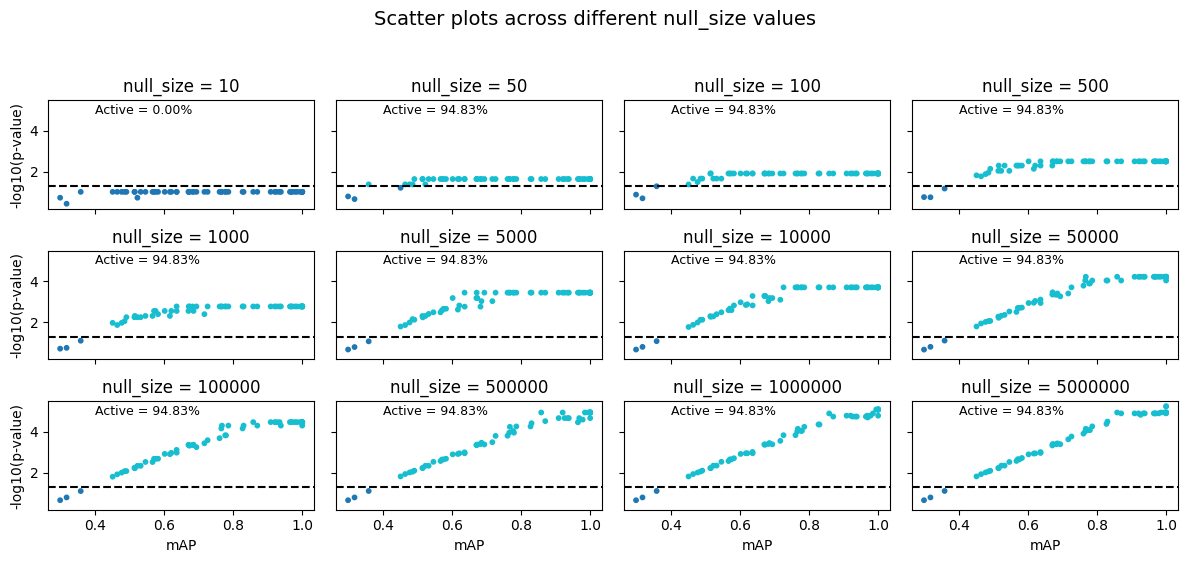

In [5]:
seed = 0

activity_maps = []
runtimes = []
for ns_pow in range(1, 7):
    for null_size in (10**ns_pow, 5 * 10**ns_pow):
        start = perf_counter()
        replicate_map = map.mean_average_precision(
            activity_ap,
            pos_sameby,
            null_size=null_size,
            threshold=0.05,
            seed=seed,
            progress_bar=False,
        )
        runtimes.append(perf_counter() - start)
        replicate_map["null_size"] = null_size
        activity_maps.append(replicate_map)

activity_maps = pd.concat(activity_maps)
activity_maps.rename(columns={"mean_average_precision": "mAP"}, inplace=True)
activity_maps["-log10(p-value)"] = -activity_maps["corrected_p_value"].apply(np.log10)

plot_scatter_grid(activity_maps)

For each null size, the table below lists the runtime, the number of compounds called active (corrected p-value < 0.05), and the mean p-value of the compounds with $m$ replicates and mAP = 1, next to the expected $p_{min}$ above.

In [6]:
n_replicates = activity_ap.groupby("Metadata_broad_sample").size()
perfect = activity_maps[
    activity_maps["Metadata_broad_sample"].isin(n_replicates[n_replicates == m].index)
    & (activity_maps["mAP"] == 1)
]
print(f"{perfect['Metadata_broad_sample'].nunique()} compounds with mAP = 1")

summary = pd.DataFrame(
    {
        "runtime (s)": np.round(runtimes, 2),
        "active": activity_maps.groupby("null_size")["below_corrected_p"].sum(),
        "p at mAP = 1 (mean)": perfect.groupby("null_size")["p_value"].mean(),
    }
)
summary["expected p_min"] = (1 + summary.index / d) / (summary.index + 1)
summary["1/d"] = 1 / d
print(summary.to_string(float_format="{:.3g}".format))

5 compounds with mAP = 1
           runtime (s)  active  p at mAP = 1 (mean)  expected p_min      1/d
null_size                                                                   
10                0.13       0               0.0909          0.0909 1.68e-06
50                 0.1      55               0.0196          0.0196 1.68e-06
100               0.11      55               0.0099          0.0099 1.68e-06
500               0.14      55                0.002           0.002 1.68e-06
1000               0.2      55             0.000999           0.001 1.68e-06
5000              0.36      55               0.0002        0.000202 1.68e-06
10000              0.4      55               0.0001        0.000102 1.68e-06
50000             1.51      55              2.4e-05        2.17e-05 1.68e-06
100000            2.85      55              1.2e-05        1.17e-05 1.68e-06
500000            13.3      55              2.8e-06        3.68e-06 1.68e-06
1000000           26.7      55              1.6e-06

The complete null has $d_{null} = 593{,}775$ relabellings for compounds with 6 replicates. With `null_size` = 10, the smallest possible p-value, $1/11$, is above 0.05 and no compound is called active. From 50 draws on, 55 of 58 compounds are active at every null size, but small null sizes cap every strong compound at the same p-value, $1/(null\_size + 1)$, and cannot rank them. The p-values of the 5 compounds with mAP = 1 follow the expected $p_{min}$, about $1/(null\_size + 1)$, up to $10^5$. From $5 \cdot 10^5$ draws on they reach the order of $1/d_{null} = 1.7 \cdot 10^{-6}$, where more draws no longer lower them. There each p-value counts only a few draws of the observed relabelling (expected $null\_size / d_{null}$, 0.8 to 8.4), so the means of 5 compounds scatter around $p_{min}$; with this seed they fall below it.

On this plate the permutation null took 27 s at $10^6$ draws and 130 s at $5 \cdot 10^6$ (16 CPUs, NumPy), so the whole grid is feasible here. Its runtime grows about linearly with `null_size`.

## Practical consideration for choosing the null size

In practice, drawing a large number of samples is not always feasible, because the permutation null's compute time grows with the number of perturbations, the sizes of perturbation groups (the number of replicates) and of the control groups they are ranked against, and the number of draws. A null size well above $d_{null}$ can still reduce Monte Carlo error, but cannot change the exact tail probability. A sampled p-value may fall below $1/d_{null}$; its floor is $1/(null\_size + 1)$. No automatic exact enumeration or adaptive stopping is performed.

Finding a `null_size` that works for a particular dataset means balancing between test resolution (for example, being able to tell apart very small p-values) and compute. We provided `null_size` values for each real-world dataset in Supplemental Materials to our paper—please refer to:

> Kalinin, A.A., Arevalo, J., Serrano, E., Vulliard, L., Tsang, H., Bornholdt, M., Muñoz, A.F., Sivagurunathan, S., Rajwa, B., Carpenter, A.E., Way, G.P. and Singh, S., 2025. A versatile information retrieval framework for evaluating profile strength and similarity. _Nature Communications_ 16, 5181. doi:10.1038/s41467-025-60306-2